# Synergy inside LLM neurons

**Mariana Meireles**, 2026

| | |
|---|---|
| **Models** | Gemma-3-4B, Gemma-3-12B (base and instruct), Qwen3-8B, Qwen2.5-32B |
| **Layers** | up to 64 |
| **Neurons per layer** | up to 25,000 (whole MLP) |
| **Prompts per model** | 6,000 |
| **Measure** | exact O-information Ω, never a proxy. **Ω < 0 = synergy**, Ω > 0 = redundancy |


## What I do

In this project I apply O-information to a Gaussian system. I build on Caprioglio, Mediano and
Berthouze's *Synergistic Motifs in Gaussian Systems*, which simplifies the O-information by expanding
its log-determinants with the Mercator series.

I apply a Gaussian-copula transform to the activations of the model's MLP units (rank-normalising each
unit, then computing the correlation matrix) and compute the O-information from the resulting
log-determinants. On top of that I developed a heuristic for finding the most synergistic subsets of
MLP units: I seed from frustrated triangles of units, then grow each triangle greedily into a larger
shape, using the smallest-eigenvalue direction of the subset's correlation matrix as a vector to
shortlist candidates. I check the exact Ω of every candidate and add the best one to the shape. I
repeat this until the shape stops growing.


## The brain-like synergistic core in LLMs

Urbina-Rodriguez et al. 2026, *A Brain-like Synergistic Core in LLMs Drives Behaviour and Learning*, Fig. 2c.
They use ΦID over **attention heads**. Synergy peaks in the **middle layers**.


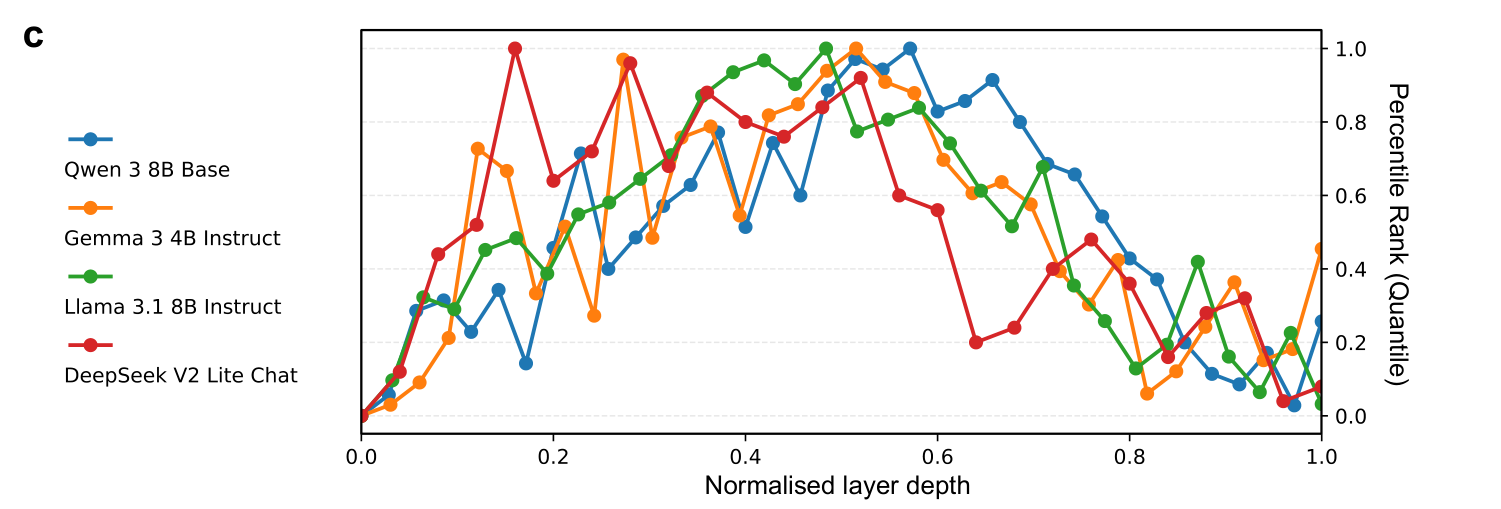

In [1]:
from IPython.display import Image, display
display(Image('showcase_assets/urbina2026_fig2c.png', width=1000))


## Our result, per neuron

Qwen3-8B, 36 layers, **individual MLP neurons**. Median exact Ω of the synergistic groups found in each
layer, size-matched to 12 units. The middle layers are the most synergistic here too.


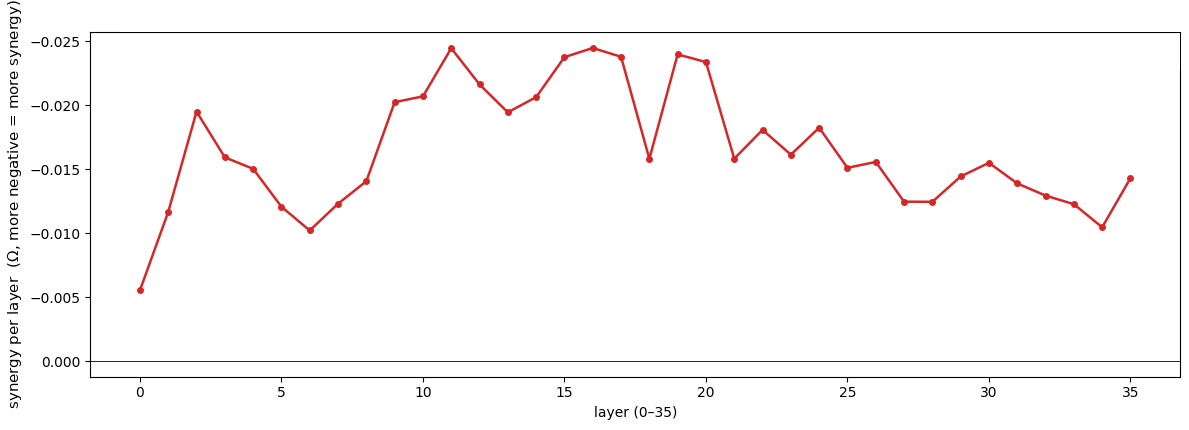

In [2]:
display(Image('showcase_assets/qwen3_8b_synergy_by_layer.png', width=1000))


Same shape, finer resolution: the synergistic core shows up at the level of single neurons, with exact
O-information, not only at the level of attention heads.


## Synergy depends on the prompt

Groups found on 6,000 prompts, then frozen and re-measured on 2,000 prompts the search never saw.
The prompts look like this:

| Category | Example prompts |
|---|---|
| **Numerical reasoning** | *A box holds 6 cans. How many cans are in 9 boxes?* · *If you have 87 apples and give away 10, how many remain?* |
| **Translation** (OOD) | *Translate the following sentence into Spanish: "We watched the sunset from the hill."* · *Translate the following sentence into Korean: "The concert was louder than I expected."* |
| **Syntax and grammar** | *Correct the error: He bringed his guitar to the party.* · *Correct the error: The artist run to the garden after lunch.* |
| **Emotional and social** | *Someone feels guilty after snapping at a friend. What is an empathetic way to start the conversation?* · *A friend cancels plans with you for the third time. What would be a thoughtful thing to do?* |
| **Part-of-speech tagging** | *Identify the parts of speech in the sentence: The bright moon slowly crossed a narrow path.* · *Tag every word with its part of speech: The curious cat suddenly noticed the crowded room.* |
| **Code generation** (OOD) | *Implement a Java function to reverse a string.* · *In C++, write code that counts the vowels in a string.* |
| **Common sense** | *Why do people wear gloves when handling something hot?* · *What is likely to happen to a box of matches if it is left in the freezer?* |
| **Abstract and creative** | *Describe the sound of the memory of rain.* · *Invent a festival celebrated only by people who have never met. Describe how it works.* |


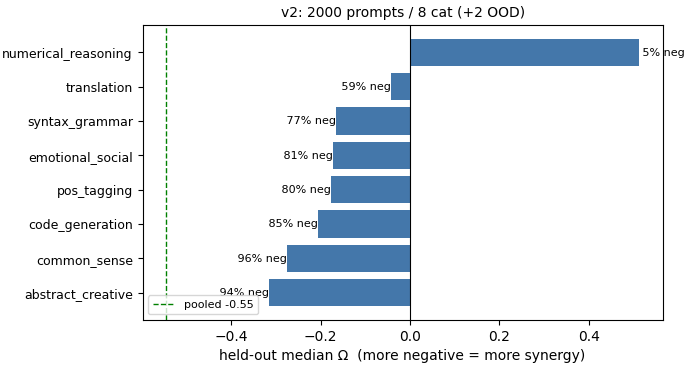

In [3]:
display(Image('showcase_assets/qwen3_8b_heldout_by_task.png', width=760))
